## Import

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from qutip import *
%matplotlib ipympl

## System setup

We will start with simple example 

$H = \frac{\Delta}{2}\sigma_x$

With dissipation 

$C = \sqrt{g} \sigma_z$

In [2]:
delta = 2*np.pi
g=0.25

H=delta/2*sigmax()

c_ops = [np.sqrt(g)*sigmaz()]

psi0 = basis(2,0)

tlist = np.linspace(0,5,100)

## Time-evolution

In [14]:
res = mesolve(H,psi0,tlist,c_ops,e_ops=[sigmaz()])

In [4]:
sz_analytic = np.cos(2 * np.pi * tlist) * np.exp(-tlist * g)

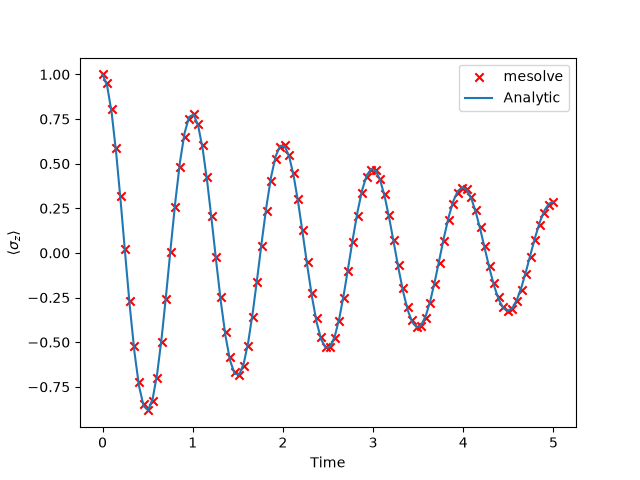

In [5]:
plt.scatter(tlist, res.expect[0], c="r", marker="x", label="mesolve")
plt.plot(tlist, sz_analytic, label="Analytic")
plt.xlabel("Time"), plt.ylabel(r"$\left<\sigma_z\right>$")
plt.legend()
plt.show()

## Qubit Dynamics on the Bloch Sphere

We consider  slightly more complex synamics of the qubite state
Hamiltonian:

$H = \Delta(\cos(\theta)\sigma_z + \sin(\theta)\sigma_x)$

In [6]:
theta = 0.2*np.pi 
H = delta * (np.cos(theta) * sigmaz() + np.sin(theta) * sigmax())

# Obtain Time Evolution
tlist = np.linspace(0, 5, 1000)
result = mesolve(H, psi0,tlist,[],e_ops=[sigmax(),sigmay(),sigmaz()])

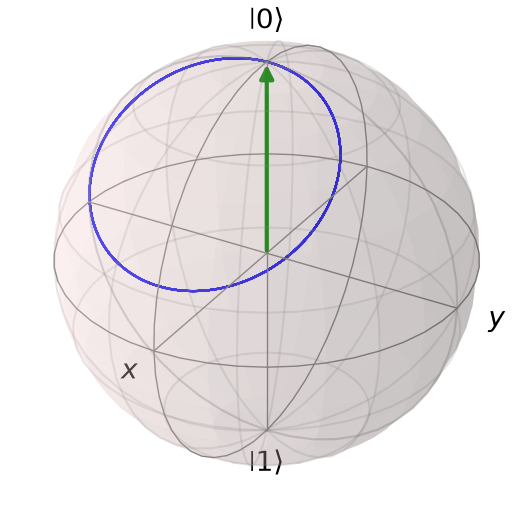

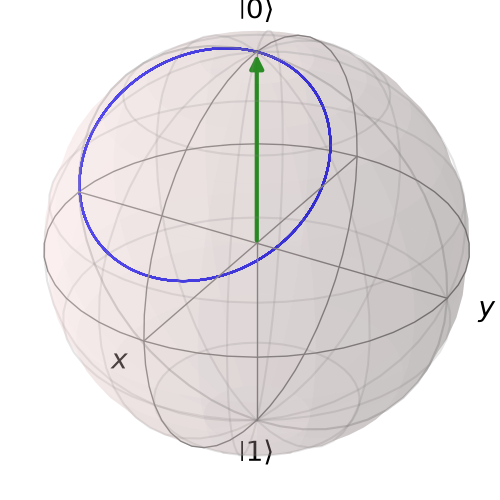

In [7]:
exp_sx_circ, exp_sy_circ, exp_sz_circ = result.expect
exp_sx_circ, exp_sy_circ, exp_sz_circ = (
    np.array(exp_sx_circ),
    np.array(exp_sy_circ),
    np.array(exp_sz_circ)
)

# Create Bloch sphere plot
sphere = Bloch()
sphere.add_points([exp_sx_circ, exp_sy_circ, exp_sz_circ],meth='l')
sphere.add_states(psi0)
sphere.show()

## Qubit dephasing

For change phase qubit we introduce the following collapse operator

$C = \sqrt{\gamma_p}\sigma_z$

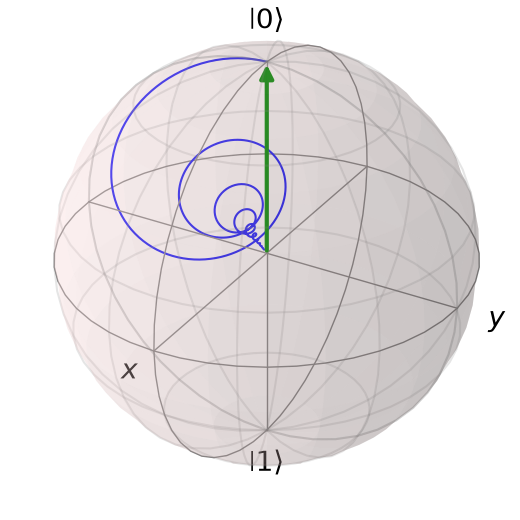

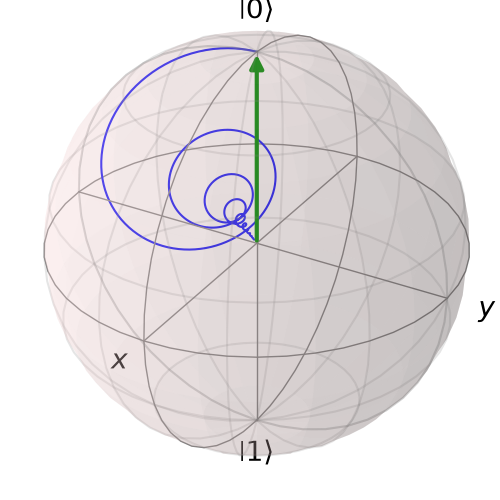

In [9]:
gamma_phase = 0.9
c_ops = [np.sqrt(gamma_phase) * sigmaz()]

# solve dynamics
result = mesolve(H, psi0, tlist, c_ops, e_ops=[sigmax(), sigmay(), sigmaz()])
exp_sx_dephase, exp_sy_dephase, exp_sz_dephase = result.expect
exp_sx_dephase, exp_sy_dephase, exp_sz_dephase = (
    np.array(exp_sx_dephase),
    np.array(exp_sy_dephase),
    np.array(exp_sz_dephase),
)

# Create Bloch sphere plot
sphere = Bloch()
sphere.add_points([exp_sx_dephase, exp_sy_dephase, exp_sz_dephase], meth="l")
sphere.add_states(psi0)
sphere.show()